# The v6 engine vs the v5 engine

The deployed parallel split root against the sequential v5 root it extends, on the same recorded game.

In [1]:
import os
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tuning" / "default.json").is_file())
os.environ["WEIGHTS_FILE"] = str(ROOT / "tuning" / "winner.json")
os.environ["V6_JOBS"] = "1"
sys.path.insert(0, str(ROOT / "tuning"))

import harness
from connect6.parallel import search_v6
from connect6.search import search_alpha_beta_with_quiescence
from connect6.vcf import search_v5

print(f"weights pinned to {os.environ['WEIGHTS_FILE']} (the shipped champion)")
print("V6_JOBS=1: the split runs in-process; node counts are the pure tree cost "
      "(the suite's V6 Test 4 pins the answer across one, three and pooled workers)")


weights pinned to /Users/e.butovka/Documents/MyProjects/Connect6Engine/tuning/winner.json (the shipped champion)
V6_JOBS=1: the split runs in-process; node counts are the pure tree cost (the suite's V6 Test 4 pins the answer across one, three and pooled workers)


## The common trajectory

The recorded game is benchmarks/trajectory.json, the 48-ply self-play shared by the version measurements.

In [2]:
import json

record = json.loads((ROOT / "benchmarks" / "trajectory.json").read_text())
history = record["history"]
assert record["outcome"] == {"winner": None, "plies": 48}
assert history[0] == "JJ" and len(history) == 49
print("common trajectory loaded: benchmarks/trajectory.json — 48 decision points, no win inside the cap")


rows = harness.analyze_history(history, [("v5", search_v5), ("v6", search_v6)], 3, jobs=12)
per_prefix = {}
for row in rows:
    per_prefix.setdefault(row.prefix, {})[row.name] = row
positions = sorted(per_prefix)
n = len(positions)

totals = {name: sum(per_prefix[p][name].nodes for p in positions) for name in ("v5", "v6")}
changes = sum(1 for p in positions if per_prefix[p]["v5"].move != per_prefix[p]["v6"].move)
flips = sum(1 for p in positions if (abs(per_prefix[p]["v5"].score) >= 20000) != (abs(per_prefix[p]["v6"].score) >= 20000))
divergences = [p for p in positions if per_prefix[p]["v5"].move != per_prefix[p]["v6"].move]
ones = [p for p in positions if per_prefix[p]["v6"].nodes == 1]
print(f"{'engine':6s} {'total nodes':>12s} {'mean/position':>13s} {'peak':>8s}")
for name in ("v5", "v6"):
    top = max(per_prefix[p][name].nodes for p in positions)
    at = max(positions, key=lambda p: per_prefix[p][name].nodes)
    print(f"{name:6s} {totals[name]:12,d} {totals[name] // n:13,d} {top:8,d} (prefix {at})")
print(f"move changes: {changes}/{n}   verdict-band flips: {flips}/{n}")
print(f"divergences: {divergences}")
print(f"one-node stage-1 answers (v6): {ones}")

common trajectory loaded: benchmarks/trajectory.json — 48 decision points, no win inside the cap


engine  total nodes mean/position     peak
v5        1,415,330        29,486  233,374 (prefix 34)
v6        3,201,750        66,703  226,843 (prefix 38)
move changes: 5/48   verdict-band flips: 0/48
divergences: [3, 19, 21, 34, 37]
one-node stage-1 answers (v6): [42, 44, 45, 46, 47]


In [3]:
EXPECTED_V6 = {
    "v5_nodes": 1415330,
    "v6_nodes": 3201750,
    "changes": 5,
    "flips": 0,
    "ones": [42, 44, 45, 46, 47],
    "v5_peak": 233374,
    "v6_peak": 226843,
    "divergences": [3, 19, 21, 34, 37],
}
assert totals["v5"] == EXPECTED_V6["v5_nodes"]
assert totals["v6"] == EXPECTED_V6["v6_nodes"]
assert changes == EXPECTED_V6["changes"]
assert flips == EXPECTED_V6["flips"]
assert ones == EXPECTED_V6["ones"]
assert max(per_prefix[p]["v5"].nodes for p in positions) == EXPECTED_V6["v5_peak"]
assert max(per_prefix[p]["v6"].nodes for p in positions) == EXPECTED_V6["v6_peak"]
assert divergences == EXPECTED_V6["divergences"]
print("the split root's answers and cost reproduce exactly "
      "(nodes, changes, flips, one-node answers, peaks, divergences)")


the split root's answers and cost reproduce exactly (nodes, changes, flips, one-node answers, peaks, divergences)


## The cost of a full window

Each split iteration spends more than the shared window; the ratio varies per position.

## The regression fixture

The terminal-break regression fixture and its per-depth cost.

In [4]:
from connect6.defines import SearchStats
from connect6.parallel import _split_root
from connect6.protocol import move2msg
from connect6.search import search_alpha_beta_with_quiescence

BLUNDER_HISTORY = "JJ IIKK JKKI IKJL IJKL LMHJ KMLJ HIHK KJJI".split()
board, pre_move, color = harness.replay_history(BLUNDER_HISTORY)
print(f"the fixture: after {len(BLUNDER_HISTORY)} plies, white to move (the ladder game that caught the bug)")

fixture = {}
for name, search in (("v5", search_v5), ("v6", search_v6)):
    stats = SearchStats()
    result = search(board, color, 3, pre_move, stats)
    fixture[name] = (move2msg(result.move), result.score, stats.node_count, stats.depth_reached)
    print(f"{name}: {fixture[name][0]} score {fixture[name][1]} {fixture[name][2]:,} nodes (depth reached {fixture[name][3]})")

costs = {}
for depth in (3, 4):
    seq = SearchStats()
    search_alpha_beta_with_quiescence(board, color, depth, pre_move, seq)
    split = SearchStats()
    _split_root(board, color, depth, pre_move, split, None)
    costs[depth] = (seq.node_count, split.node_count)
    print(f"depth {depth}: shared window {seq.node_count:6,d} nodes, split {split.node_count:6,d} nodes "
          f"({split.node_count / max(seq.node_count, 1):.2f}x)")


the fixture: after 9 plies, white to move (the ladder game that caught the bug)


v5: MJHL score -402 20,583 nodes (depth reached 0)


v6: MJHL score -402 51,637 nodes (depth reached 4)


depth 3: shared window  1,951 nodes, split 12,800 nodes (6.56x)


depth 4: shared window 18,626 nodes, split 38,831 nodes (2.08x)


In [5]:
EXPECTED_FIXTURE = {
    "v5": ("MJHL", -402, 20583),
    "v6": ("MJHL", -402, 51637, 4),
    "cost3": (1951, 12800),
    "cost4": (18626, 38831),
}
assert fixture["v5"][:3] == EXPECTED_FIXTURE["v5"]
assert fixture["v6"] == EXPECTED_FIXTURE["v6"]
assert costs[3] == EXPECTED_FIXTURE["cost3"]
assert costs[4] == EXPECTED_FIXTURE["cost4"]
print(f"the fixture holds: both roots answer MJHL, and the split's cost at depth 3 is {costs[3][1] / costs[3][0]:.2f}x")


the fixture holds: both roots answer MJHL, and the split's cost at depth 3 is 6.56x


## The window and the scouts, by depth

Three positions at depths 1-5: shared window, plain-subtree split, deployed scouted split.

In [6]:
import time

from connect6.board import copy_board, make_move, opponent
from connect6.candidates import generate_scored_candidate_moves
from connect6.defines import FORWARD_WIDTHS, MAXINT, MININT, Color
from connect6.search import _alpha_beta

BLUNDER_HISTORY = "JJ IIKK JKKI IKJL IJKL LMHJ KMLJ HIHK KJJI".split()
WINDOW_DEPTHS = (1, 2, 3, 4, 5)


def ladder_positions():
    fixture_board, fixture_pre, fixture_color = harness.replay_history(BLUNDER_HISTORY)
    yield "regression fixture, white to move", fixture_board, fixture_color, fixture_pre
    for label, board, color, pre in harness.documented_positions():
        if label in ("midgame, white to move", "five-run attack, white to move"):
            yield label, board, color, pre


def split_loop(board, color, depth, pvs):
    candidates, threats = generate_scored_candidate_moves(board, FORWARD_WIDTHS[0], color)
    if not candidates:
        return 1, None, None
    maximizing = color == Color.BLACK
    best_score = MININT if maximizing else MAXINT
    best_move = candidates[0]
    nodes = 1
    for index, candidate in enumerate(candidates):
        work = copy_board(board)
        make_move(work, candidate, color)
        stats = SearchStats()
        result = _alpha_beta(
            depth - 1, work, opponent(color), candidate, stats, MININT, MAXINT, True, True, 1,
            threats[index] if threats[index] > 0 else 0, pvs,
        )
        nodes += stats.node_count
        if (maximizing and result.score > best_score) or (not maximizing and result.score < best_score):
            best_score, best_move = result.score, candidate
        if best_score == (MAXINT if maximizing else MININT):
            break
    return nodes, best_move, best_score


window_ladder = {}
for label, board, color, pre in ladder_positions():
    for depth in WINDOW_DEPTHS:
        shared_stats = SearchStats()
        start = time.perf_counter()
        shared = search_alpha_beta_with_quiescence(board, color, depth, pre, shared_stats)
        shared_ms = (time.perf_counter() - start) * 1000
        split_stats = SearchStats()
        start = time.perf_counter()
        split, _ = _split_root(board, color, depth, pre, split_stats, None)
        split_ms = (time.perf_counter() - start) * 1000
        base_total, base_move, base_score = split_loop(board, color, depth, False)
        pvs_total, pvs_move, pvs_score = split_loop(board, color, depth, True)
        assert split_stats.node_count == pvs_total, (label, depth, "engine calibration")
        assert base_score == pvs_score == split.score == shared.score, (label, depth, "scores")
        cells = lambda m: tuple(sorted((p.x, p.y) for p in m.positions))
        assert cells(base_move) == cells(pvs_move) == cells(split.move) == cells(shared.move), (label, depth, "moves")
        window_ladder[(label, depth)] = {
            "shared": (shared_stats.node_count, shared_ms),
            "base": (base_total, 0.0),
            "pvs": (pvs_total, split_ms),
        }
    print(f"== {label} ==")
    print(f"{'depth':5} {'shared':>9} {'growth':>6} {'split base':>11} {'growth':>6} {'split pvs':>10} "
          f"{'growth':>6} {'window':>7} {'scout cut':>9}")
    for depth in WINDOW_DEPTHS:
        s, b, p = (window_ladder[(label, depth)][k][0] for k in ("shared", "base", "pvs"))
        s_g = "-" if depth == 1 else f"x{s / window_ladder[(label, depth - 1)]['shared'][0]:.1f}"
        b_g = "-" if depth == 1 else f"x{b / window_ladder[(label, depth - 1)]['base'][0]:.1f}"
        p_g = "-" if depth == 1 else f"x{p / window_ladder[(label, depth - 1)]['pvs'][0]:.1f}"
        print(f"d{depth:<4} {s:>9,d} {s_g:>6} {b:>11,d} {b_g:>6} {p:>10,d} {p_g:>6} "
              f"x{p / s:>6.2f} x{b / p:>8.3f}")
    print()

== regression fixture, white to move ==
depth    shared growth  split base growth  split pvs growth  window scout cut
d1           58      -          94      -         94      - x  1.62 x   1.000
d2        2,337  x40.3       3,581  x38.1      3,722  x39.6 x  1.59 x   0.962
d3        1,951   x0.8      12,657   x3.5     12,800   x3.4 x  6.56 x   0.989
d4       18,626   x9.5      54,957   x4.3     38,831   x3.0 x  2.08 x   1.415
d5       35,221   x1.9     214,759   x3.9    136,354   x3.5 x  3.87 x   1.575



== midgame, white to move ==
depth    shared growth  split base growth  split pvs growth  window scout cut
d1           67      -         103      -        103      - x  1.54 x   1.000
d2          402   x6.0       1,093  x10.6      1,103  x10.7 x  2.74 x   0.991
d3        1,458   x3.6      27,151  x24.8     10,005   x9.1 x  6.86 x   2.714
d4        3,782   x2.6      25,117   x0.9     28,401   x2.8 x  7.51 x   0.884
d5       18,165   x4.8     182,486   x7.3    178,810   x6.3 x  9.84 x   1.021



== five-run attack, white to move ==
depth    shared growth  split base growth  split pvs growth  window scout cut
d1           31      -          31      -         31      - x  1.00 x   1.000
d2           87   x2.8          87   x2.8         96   x3.1 x  1.10 x   0.906
d3          103   x1.2         103   x1.2        120   x1.2 x  1.17 x   0.858
d4          110   x1.1         110   x1.1        110   x0.9 x  1.00 x   1.000
d5          112   x1.0         112   x1.0        112   x1.0 x  1.00 x   1.000



In [7]:
EXPECTED_WINDOW = {
    ("regression fixture, white to move", 1): (58, 94, 94),
    ("regression fixture, white to move", 2): (2337, 3581, 3722),
    ("regression fixture, white to move", 3): (1951, 12657, 12800),
    ("regression fixture, white to move", 4): (18626, 54957, 38831),
    ("regression fixture, white to move", 5): (35221, 214759, 136354),
    ("midgame, white to move", 1): (67, 103, 103),
    ("midgame, white to move", 2): (402, 1093, 1103),
    ("midgame, white to move", 3): (1458, 27151, 10005),
    ("midgame, white to move", 4): (3782, 25117, 28401),
    ("midgame, white to move", 5): (18165, 182486, 178810),
    ("five-run attack, white to move", 1): (31, 31, 31),
    ("five-run attack, white to move", 2): (87, 87, 96),
    ("five-run attack, white to move", 3): (103, 103, 120),
    ("five-run attack, white to move", 4): (110, 110, 110),
    ("five-run attack, white to move", 5): (112, 112, 112),
}
for key, (shared, base, pvs) in EXPECTED_WINDOW.items():
    measured = window_ladder[key]
    assert (measured["shared"][0], measured["base"][0], measured["pvs"][0]) == (shared, base, pvs), key
assert (window_ladder[("regression fixture, white to move", 3)]["shared"][0],
        window_ladder[("regression fixture, white to move", 3)]["pvs"][0]) == EXPECTED_FIXTURE["cost3"]
assert (window_ladder[("regression fixture, white to move", 4)]["shared"][0],
        window_ladder[("regression fixture, white to move", 4)]["pvs"][0]) == EXPECTED_FIXTURE["cost4"]
print("the window ladder pins all three variants at every depth and reproduces "
      "the fixture's cost pair (1,951/12,800 at depth 3, 18,626/38,831 at depth 4)")

the window ladder pins all three variants at every depth and reproduces the fixture's cost pair (1,951/12,800 at depth 3, 18,626/38,831 at depth 4)


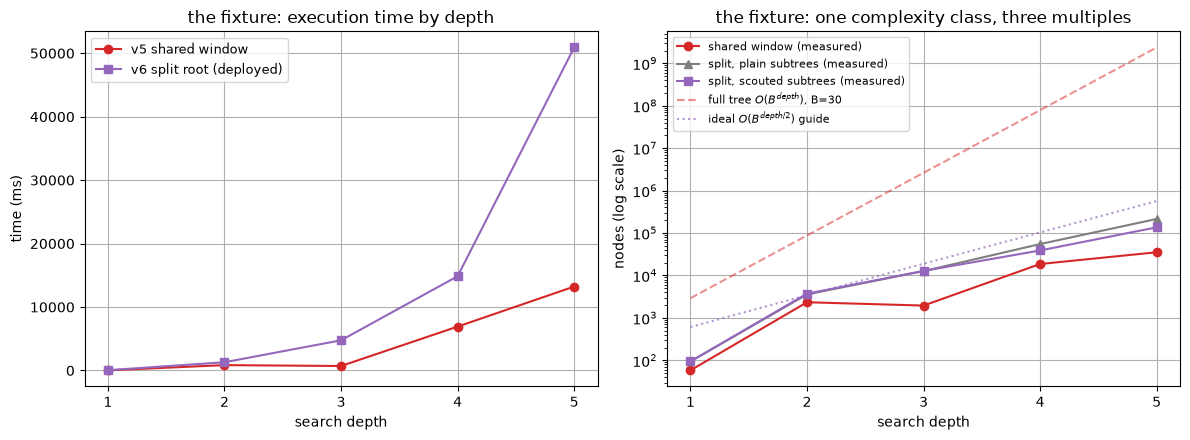

In [8]:
import matplotlib.pyplot as plt

BRANCHING = 30
fixture = "regression fixture, white to move"
depths = WINDOW_DEPTHS
shared = [window_ladder[(fixture, d)]["shared"][0] for d in depths]
base = [window_ladder[(fixture, d)]["base"][0] for d in depths]
pvs = [window_ladder[(fixture, d)]["pvs"][0] for d in depths]
shared_ms = [window_ladder[(fixture, d)]["shared"][1] for d in depths]
pvs_ms = [window_ladder[(fixture, d)]["pvs"][1] for d in depths]
anchor = base[0]
full_tree = [anchor * sum(BRANCHING ** k for k in range(d + 1)) for d in depths]
ideal_tree = [anchor * sum(BRANCHING ** (k / 2) for k in range(d + 1)) for d in depths]

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax.plot(depths, shared_ms, marker="o", color="tab:red", label="v5 shared window")
ax.plot(depths, pvs_ms, marker="s", color="tab:purple", label="v6 split root (deployed)")
ax.set_xlabel("search depth")
ax.set_ylabel("time (ms)")
ax.set_title("the fixture: execution time by depth")
ax.set_xticks(depths)
ax.grid(True)
ax.legend(fontsize=9)

ax2.semilogy(depths, shared, marker="o", color="tab:red", label="shared window (measured)")
ax2.semilogy(depths, base, marker="^", color="tab:gray", label="split, plain subtrees (measured)")
ax2.semilogy(depths, pvs, marker="s", color="tab:purple", label="split, scouted subtrees (measured)")
ax2.semilogy(depths, full_tree, linestyle="--", color="tab:red", alpha=0.5, label=f"full tree $O(B^{{depth}})$, B={BRANCHING}")
ax2.semilogy(depths, ideal_tree, linestyle=":", color="tab:purple", alpha=0.7, label=f"ideal $O(B^{{depth/2}})$ guide")
ax2.set_xlabel("search depth")
ax2.set_ylabel("nodes (log scale)")
ax2.set_title("the fixture: one complexity class, three multiples")
ax2.set_xticks(depths)
ax2.grid(True)
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

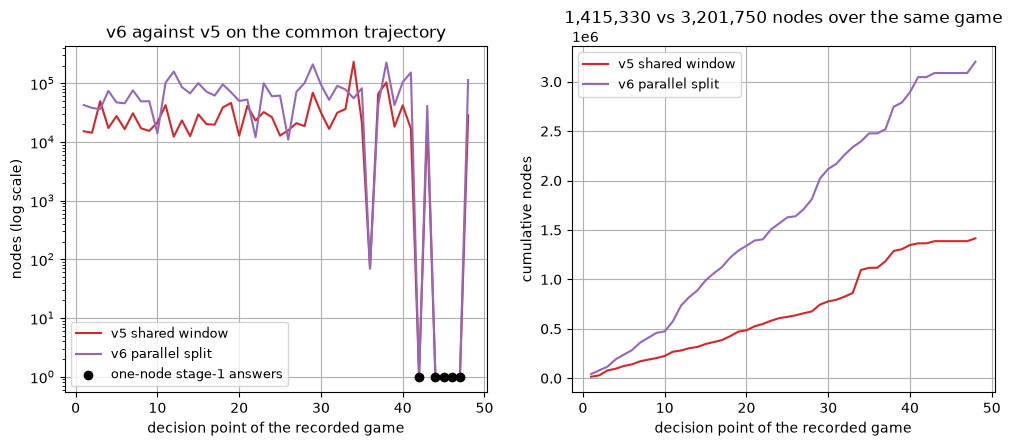

In [9]:
import matplotlib.pyplot as plt

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax.plot(positions, [per_prefix[p]["v5"].nodes for p in positions], color="tab:red", label="v5 shared window")
ax.plot(positions, [per_prefix[p]["v6"].nodes for p in positions], color="tab:purple", label="v6 parallel split")
ax.scatter(ones, [1] * len(ones), color="black", zorder=3, label="one-node stage-1 answers")
ax.set_yscale("log")
ax.set_xlabel("decision point of the recorded game")
ax.set_ylabel("nodes (log scale)")
ax.set_title("v6 against v5 on the common trajectory")
ax.grid(True)
ax.legend(fontsize=9)
ax2.plot(positions, [sum(per_prefix[q]["v5"].nodes for q in positions[:i + 1]) for i, p in enumerate(positions)], color="tab:red", label="v5 shared window")
ax2.plot(positions, [sum(per_prefix[q]["v6"].nodes for q in positions[:i + 1]) for i, p in enumerate(positions)], color="tab:purple", label="v6 parallel split")
ax2.set_xlabel("decision point of the recorded game")
ax2.set_ylabel("cumulative nodes")
ax2.set_title(f"{totals['v5']:,} vs {totals['v6']:,} nodes over the same game")
ax2.grid(True)
ax2.legend(fontsize=9)
plt.show()


## Reading the results

The split keeps every verdict at a higher node cost; PVS claws part of it back.